# T33 · Números e figuras do relatório: resultados e interpretação

**Issue:** #33 · **Fase 5 · Entrega** · Seções **6 (Resultados)** e **7 (Interpretação)** de `results/relatorio_tecnico.md`

Este notebook é a **rastreabilidade** da seção: todo número citado no relatório é calculado aqui, a partir dos arquivos e do código do projeto, e não digitado
à mão. Ele também gera as figuras novas da seção (`results/figures/t33_*.png`).

> **O teste não é reavaliado.** O resultado final no teste vem de `results/test_results.csv` (a avaliação única da T23). A matriz de confusão do teste é
> **reconstruída** a partir das taxas desse arquivo e da contagem de doentes e saudáveis dos rótulos do teste, sem rodar o modelo de novo.
> As métricas na validação usam os modelos treinados **só no treino**, com os hiperparâmetros padrão de cada `estimators/*.py`.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from cardio.config import FIGURES_DIR, RESULTS_DIR, SEED, THRESHOLD_MIN_RECALL, VAL_RESULTS_PATH
from cardio.data.preprocessing import build_preprocessor, load_splits
from cardio.models.estimators import logistic, random_forest, xgb
from cardio.models.evaluate import choose_threshold, impact_per_1000, threshold_curve, validation_probabilities
from cardio.models.explain import (
    importancia_nativa,
    importancia_por_permutacao,
    odds_ratios_clinicos,
    shap_por_faixa,
    shap_values,
)
from cardio.models.final_model import FINAL_MODEL_PATH, LIMIAR_FINAL, train_final_model
from cardio.visualization.plots import plot_confusion_matrix, plot_threshold_curve

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
NOMES = {"logistic": "Regressão Logística", "knn": "KNN", "random_forest": "Random Forest", "xgb": "XGBoost", "svm": "SVM",
         "baseline": "Baseline (sorteio)"}


def mostrar(caminho) -> None:
    """Mostra uma figura já salva em results/figures/."""
    display(Image(filename=str(caminho)))


def pct(valor: float, casas: int = 0) -> str:
    """Formata uma proporção (0–1) como porcentagem no padrão brasileiro: 0.497 -> '49,7%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    """Formata um número com vírgula decimal: 0.238 -> '0,24'."""
    return f"{valor:.{casas}f}".replace(".", ",")


def inteiro(valor: int) -> str:
    """Formata um inteiro com ponto de milhar: 10277 -> '10.277'."""
    return f"{int(valor):,}".replace(",", ".")


def texto(conteudo: str) -> None:
    """Mostra um texto formatado em Markdown."""
    display(Markdown(conteudo))

## 1. Comparação dos modelos na validação (seção 6.2)

Tabela de `results/val_results.csv` (resultado mais recente de cada modelo e conjunto) com o baseline de `results/comparison_table.csv`.
O **SVM** está em `val_results.csv`, mas **não** em `comparison_table.csv`, `thresholds.csv` e `adjusted_metrics.csv` (T22 e T23), por isso a tabela parte do primeiro.
Limiar padrão de 0,50.

In [2]:
colunas = ["modelo", "features", "acuracia", "precision_score", "recall_score", "f1_score", "auc_roc"]
val = pd.read_csv(VAL_RESULTS_PATH).drop_duplicates(["modelo", "features"], keep="last")
baseline = pd.read_csv(RESULTS_DIR / "comparison_table.csv").query("modelo == 'baseline'")
comp = pd.concat([val[colunas], baseline[colunas]], ignore_index=True)
A, B = (comp[comp["features"] == c].set_index("modelo") for c in ("A", "B"))
ordem = A.sort_values("auc_roc", ascending=False).index

linhas = ["| Modelo | Acurácia | Precision | Recall | F1 | AUC (conjunto A) | AUC (conjunto B) |", "|---|---|---|---|---|---|---|"]
for m in ordem:
    r = A.loc[m]
    linhas.append(f"| {NOMES[m]} | {pct(r.acuracia, 1)} | {pct(r.precision_score, 1)} | {pct(r.recall_score, 1)} | {pct(r.f1_score, 1)} | {num(r.auc_roc, 3)} | {num(B.loc[m, 'auc_roc'], 3)} |")
texto("\n".join(linhas))

modelos5 = [m for m in ordem if m != "baseline"]
print("modelos:", len(modelos5), "| AUC (A) de", num(A.loc[modelos5, "auc_roc"].min(), 3), "a", num(A.loc[modelos5, "auc_roc"].max(), 3))
print("maior diferença de AUC entre os conjuntos A e B:", num((A.loc[modelos5, "auc_roc"] - B.loc[modelos5, "auc_roc"]).abs().max(), 3))
print("baseline: acurácia", pct(A.loc["baseline", "acuracia"], 1), "| AUC", num(A.loc["baseline", "auc_roc"], 3))

| Modelo | Acurácia | Precision | Recall | F1 | AUC (conjunto A) | AUC (conjunto B) |
|---|---|---|---|---|---|---|
| XGBoost | 72,6% | 74,5% | 67,9% | 71,1% | 0,792 | 0,792 |
| SVM | 72,8% | 74,1% | 69,3% | 71,6% | 0,792 | 0,791 |
| Random Forest | 72,9% | 75,2% | 67,3% | 71,1% | 0,791 | 0,790 |
| KNN | 72,5% | 75,3% | 66,0% | 70,4% | 0,785 | 0,786 |
| Regressão Logística | 72,7% | 75,0% | 67,1% | 70,8% | 0,783 | 0,785 |
| Baseline (sorteio) | 50,9% | 50,4% | 49,4% | 49,9% | 0,508 | 0,508 |

modelos: 5 | AUC (A) de 0,783 a 0,792
maior diferença de AUC entre os conjuntos A e B: 0,002
baseline: acurácia 50,9% | AUC 0,508


## 2. Curvas ROC, Precision-Recall e calibração (seção 6.2)

As figuras vêm da T21 (`roc_A.png`, `pr_A.png`, `calibration_xgb.png`). Aqui os modelos são treinados de novo (mesma `SEED`) só para **conferir os números** que o relatório cita.

In [3]:
probs, y_val = validation_probabilities("A")
metricas = pd.DataFrame(
    {NOMES[m]: {"AUC": roc_auc_score(y_val, p), "AP": average_precision_score(y_val, p)} for m, p in probs.items()}
).T.sort_values("AUC", ascending=False)

frac_real, prob_media = calibration_curve(y_val, probs["xgb"], n_bins=10)
por_faixa = np.histogram(probs["xgb"], bins=10, range=(0, 1))[0]
por_faixa = por_faixa[por_faixa > 0]  # o calibration_curve descarta as faixas vazias
desvio_calibracao = np.abs(frac_real - prob_media)
desvio_ponderado = float((desvio_calibracao * por_faixa).sum() / por_faixa.sum())
print(f"prevalência de doença na validação: {pct(y_val.mean(), 1)} (n = {inteiro(len(y_val))})")
print(f"calibração do XGBoost (10 faixas): desvio médio de {num(desvio_ponderado * 100, 1)} pontos percentuais entre a probabilidade prevista e a frequência real (ponderado pelo número de pacientes)")
print(f"pacientes por faixa de probabilidade: {por_faixa.tolist()} (a última faixa tem poucos pacientes, então o desvio máximo por faixa engana)")
metricas.round(4)

prevalência de doença na validação: 49,5% (n = 10.277)
calibração do XGBoost (10 faixas): desvio médio de 1,5 pontos percentuais entre a probabilidade prevista e a frequência real (ponderado pelo número de pacientes)
pacientes por faixa de probabilidade: [278, 1113, 1761, 1479, 1035, 875, 626, 660, 2445, 5] (a última faixa tem poucos pacientes, então o desvio máximo por faixa engana)


,AUC,AP
XGBoost,0.7919,0.7762
SVM,0.7915,0.7742
Random Forest,0.7908,0.7747
KNN,0.7853,0.7649
Regressão Logística,0.7831,0.7614


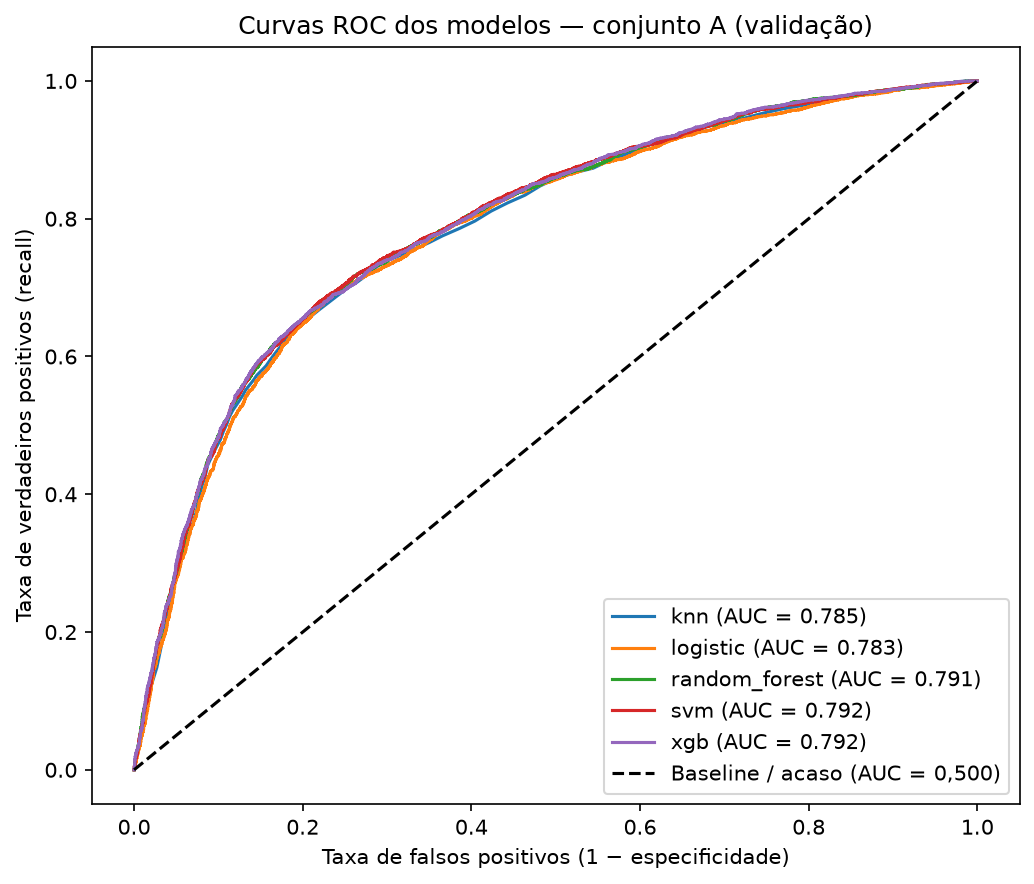

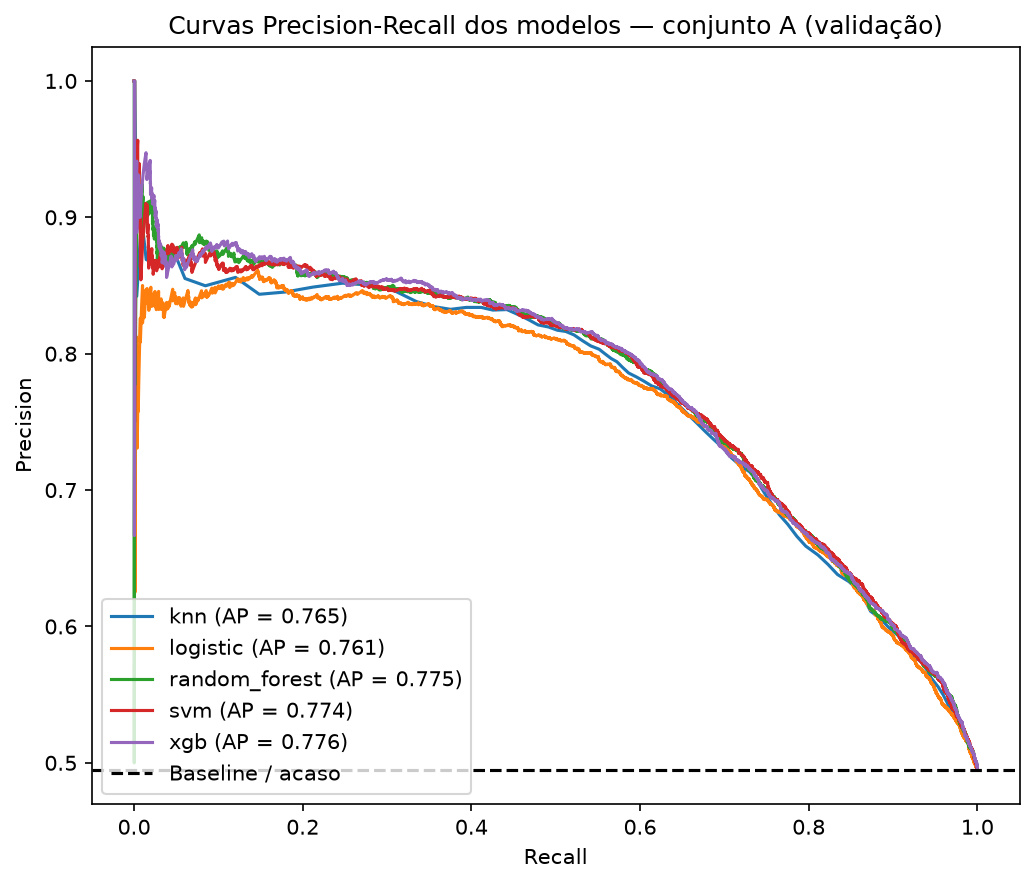

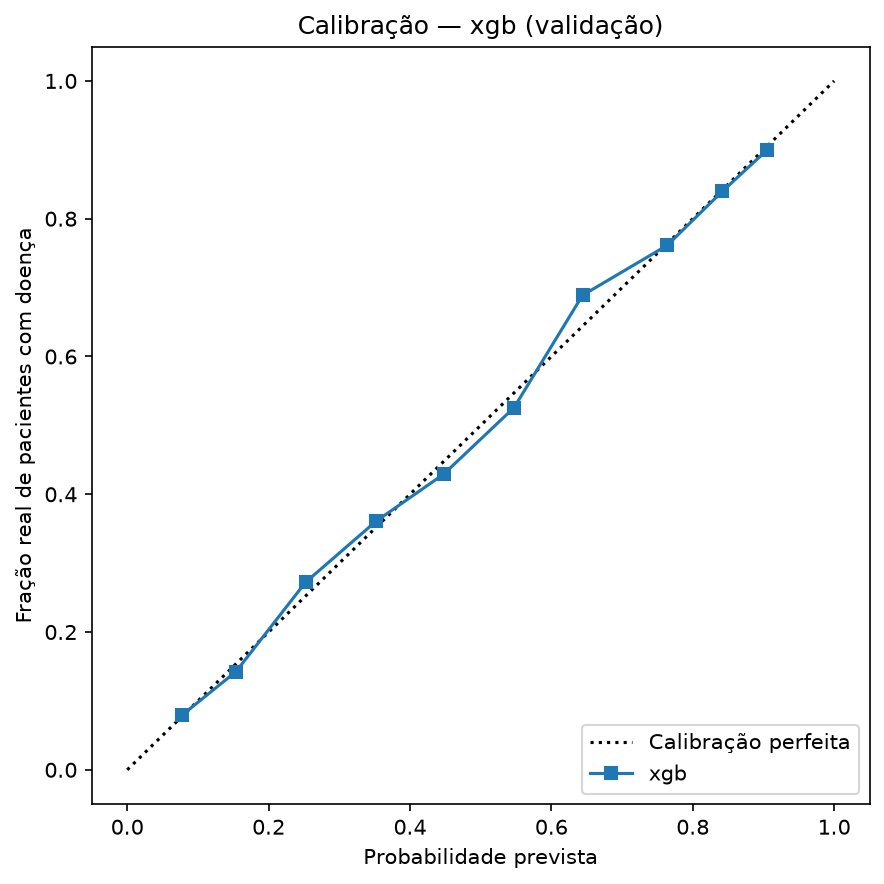

In [4]:
for arquivo in ("roc_A.png", "pr_A.png", "calibration_xgb.png"):
    mostrar(FIGURES_DIR / arquivo)

## 3. Limiar de decisão do modelo final, XGBoost com o conjunto A (seção 6.3)

A figura e a tabela da T22 (`threshold.png`) são do **XGBoost com o conjunto B**; o modelo final é o **conjunto A**, então a curva e o impacto por 1.000 pacientes são refeitos aqui.

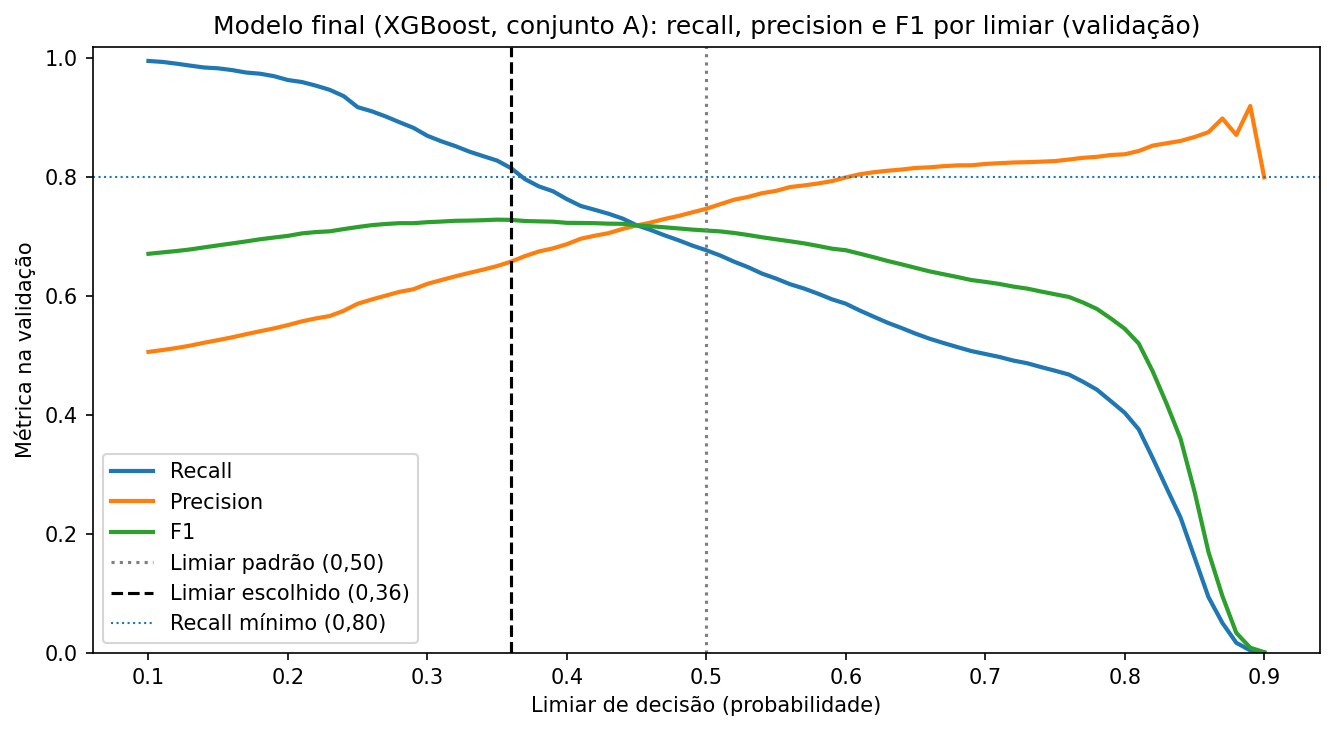

| | Limiar 0,50 | Limiar 0,36 | Diferença |
|---|---|---|---|
| Recall | 67,7% | 81,5% | +13,8 p.p. |
| Precision | 74,7% | 65,8% | -8,9 p.p. |
| Especificidade | 77,5% | 58,5% | -19,0 p.p. |
| Doentes **não sinalizados** por 1.000 pacientes | 160 | 91 | -68 |
| Saudáveis **encaminhados** por 1.000 pacientes | 113 | 209 | +96 |

doentes a mais sinalizados por 1.000: 68 | encaminhamentos extras por 1.000: 96 | alarmes falsos por doente a mais: 1,4


In [5]:
proba = probs["xgb"]
curva = threshold_curve(y_val, proba)
limiar = choose_threshold(y_val, proba)
assert limiar == LIMIAR_FINAL, (limiar, LIMIAR_FINAL)  # a regra da T22 reproduz o limiar fixado na T23

caminho = plot_threshold_curve(
    curva, limiar, FIGURES_DIR / "t33_limiar_xgb_A.png", min_recall=THRESHOLD_MIN_RECALL,
    title="Modelo final (XGBoost, conjunto A): recall, precision e F1 por limiar (validação)",
)
mostrar(caminho)

padrao, ajustado = impact_per_1000(y_val, proba, 0.5), impact_per_1000(y_val, proba, limiar)
nao_sinal, encam = "doentes_nao_sinalizados_por_1000", "saudaveis_encaminhados_por_1000"
texto(f"""| | Limiar 0,50 | Limiar {num(limiar)} | Diferença |
|---|---|---|---|
| Recall | {pct(padrao["recall"], 1)} | {pct(ajustado["recall"], 1)} | {f"{(ajustado['recall'] - padrao['recall']) * 100:+.1f}".replace(".", ",")} p.p. |
| Precision | {pct(padrao["precision"], 1)} | {pct(ajustado["precision"], 1)} | {f"{(ajustado['precision'] - padrao['precision']) * 100:+.1f}".replace(".", ",")} p.p. |
| Especificidade | {pct(padrao["especificidade"], 1)} | {pct(ajustado["especificidade"], 1)} | {f"{(ajustado['especificidade'] - padrao['especificidade']) * 100:+.1f}".replace(".", ",")} p.p. |
| Doentes **não sinalizados** por 1.000 pacientes | {padrao[nao_sinal]:.0f} | {ajustado[nao_sinal]:.0f} | {ajustado[nao_sinal] - padrao[nao_sinal]:+.0f} |
| Saudáveis **encaminhados** por 1.000 pacientes | {padrao[encam]:.0f} | {ajustado[encam]:.0f} | {ajustado[encam] - padrao[encam]:+.0f} |""")

ajustes = pd.read_csv(RESULTS_DIR / "adjusted_metrics.csv").query("modelo == 'xgb' and features == 'A'").iloc[0]
# confere com a T22; tolerância de 0,5 p.p. porque o XGBoost varia um pouco entre máquinas
assert abs(ajustes["recall_ajustado"] - ajustado["recall"]) < 5e-3, (ajustes["recall_ajustado"], ajustado["recall"])
extras = (padrao[nao_sinal] - ajustado[nao_sinal], ajustado[encam] - padrao[encam])
print(f"doentes a mais sinalizados por 1.000: {extras[0]:.0f} | encaminhamentos extras por 1.000: {extras[1]:.0f} | alarmes falsos por doente a mais: {num(extras[1] / extras[0], 1)}")

## 4. Resultado final no conjunto de teste (seção 6.4)

`results/test_results.csv` guarda a avaliação única da T23 (XGBoost, conjunto A, limiar 0,36). A matriz de confusão é **reconstruída**: com as taxas publicadas e o número
de doentes e saudáveis do teste, as quatro contagens saem exatas (e conferem com a precision e a acurácia do arquivo).

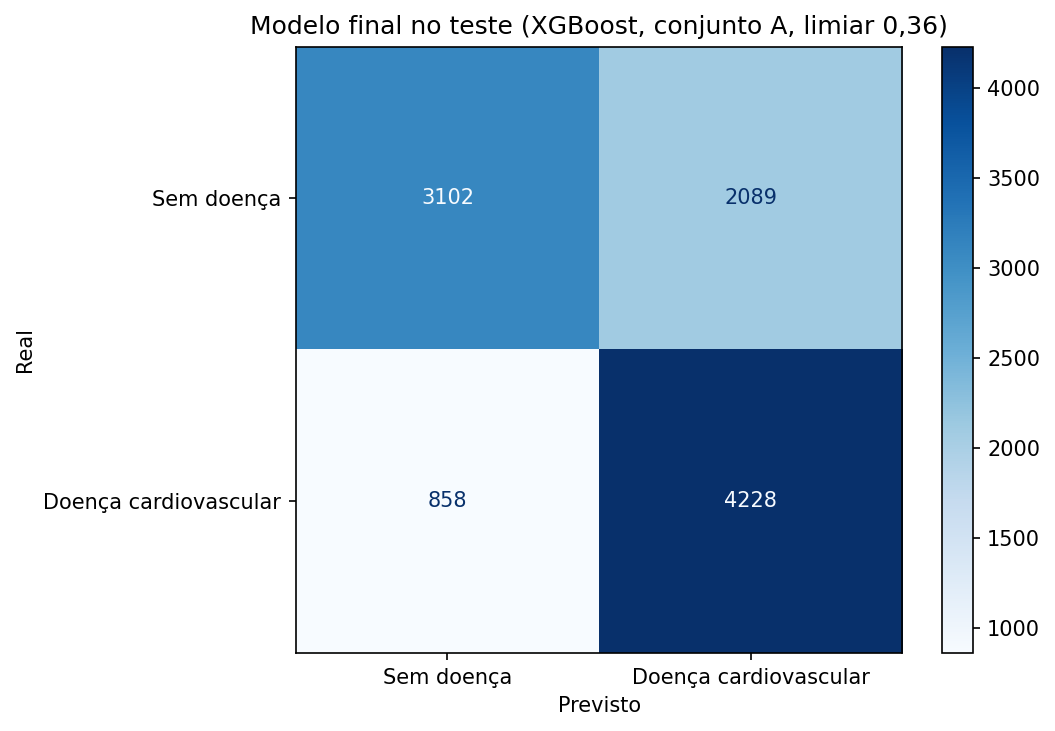

| Métrica | Valor |
|---|---|
| Pacientes no teste | 10.277 (5.086 com doença, 5.191 sem) |
| AUC ROC | 0,810 |
| Recall | 83,1% |
| Precision | 66,9% |
| F1-score | 74,2% |
| Especificidade | 59,8% |
| Acurácia | 71,3% |

Matriz: **4.228** doentes sinalizados, **858** doentes não sinalizados, **2.089** saudáveis encaminhados, **3.102** saudáveis liberados.
A cada 1.000 pacientes (49,5% doentes): 411 doentes sinalizados, **83 não sinalizados**, **203 saudáveis encaminhados**, 302 saudáveis liberados.
Alarmes verdadeiros: 67% (67 a cada 100 sinalizados têm a doença).

AUC no teste (0,810) menos AUC na validação do XGBoost A (0,792): +0.018


In [6]:
teste = pd.read_csv(RESULTS_DIR / "test_results.csv").iloc[0]
*_, y_test = load_splits("A", save_ids=False)  # só os rótulos, para contar doentes e saudáveis
n = int(teste["n_pacientes"])
assert n == len(y_test)
P, N = int(y_test.sum()), int((y_test == 0).sum())

vp, vn = teste["recall"] * P, teste["especificidade"] * N
assert abs(vp - round(vp)) < 1e-6 and abs(vn - round(vn)) < 1e-6  # taxas = contagens exatas
vp, vn = int(round(vp)), int(round(vn))
fn, fp = P - vp, N - vn
assert abs(vp / (vp + fp) - teste["precision"]) < 1e-9 and abs((vp + vn) / n - teste["accuracy"]) < 1e-9
assert abs(fn / n * 1000 - teste["doentes_nao_sinalizados_por_1000"]) < 1e-6

y_real = np.r_[np.ones(vp + fn), np.zeros(fp + vn)]
y_prev = np.r_[np.ones(vp), np.zeros(fn), np.ones(fp), np.zeros(vn)]
mostrar(plot_confusion_matrix(y_real, y_prev, FIGURES_DIR / "t33_matriz_confusao_teste.png",
                              f"Modelo final no teste (XGBoost, conjunto A, limiar {num(teste['limiar'])})"))

texto(f"""| Métrica | Valor |
|---|---|
| Pacientes no teste | {inteiro(n)} ({inteiro(P)} com doença, {inteiro(N)} sem) |
| AUC ROC | {num(teste["auc_roc"], 3)} |
| Recall | {pct(teste["recall"], 1)} |
| Precision | {pct(teste["precision"], 1)} |
| F1-score | {pct(teste["f1"], 1)} |
| Especificidade | {pct(teste["especificidade"], 1)} |
| Acurácia | {pct(teste["accuracy"], 1)} |

Matriz: **{inteiro(vp)}** doentes sinalizados, **{inteiro(fn)}** doentes não sinalizados, **{inteiro(fp)}** saudáveis encaminhados, **{inteiro(vn)}** saudáveis liberados.
A cada 1.000 pacientes ({pct(P / n, 1)} doentes): {vp / n * 1000:.0f} doentes sinalizados, **{fn / n * 1000:.0f} não sinalizados**, **{fp / n * 1000:.0f} saudáveis encaminhados**, {vn / n * 1000:.0f} saudáveis liberados.
Alarmes verdadeiros: {pct(vp / (vp + fp))} ({vp / (vp + fp) * 100:.0f} a cada 100 sinalizados têm a doença).""")
print(f"AUC no teste ({num(teste['auc_roc'], 3)}) menos AUC na validação do XGBoost A ({num(roc_auc_score(y_val, proba), 3)}): {teste['auc_roc'] - roc_auc_score(y_val, proba):+.3f}")

## 5. Por que o desempenho para perto de 0,79? (seção 6.5)

Quatro verificações rápidas com o XGBoost no conjunto A (AUC na validação). Todas treinam só no treino.

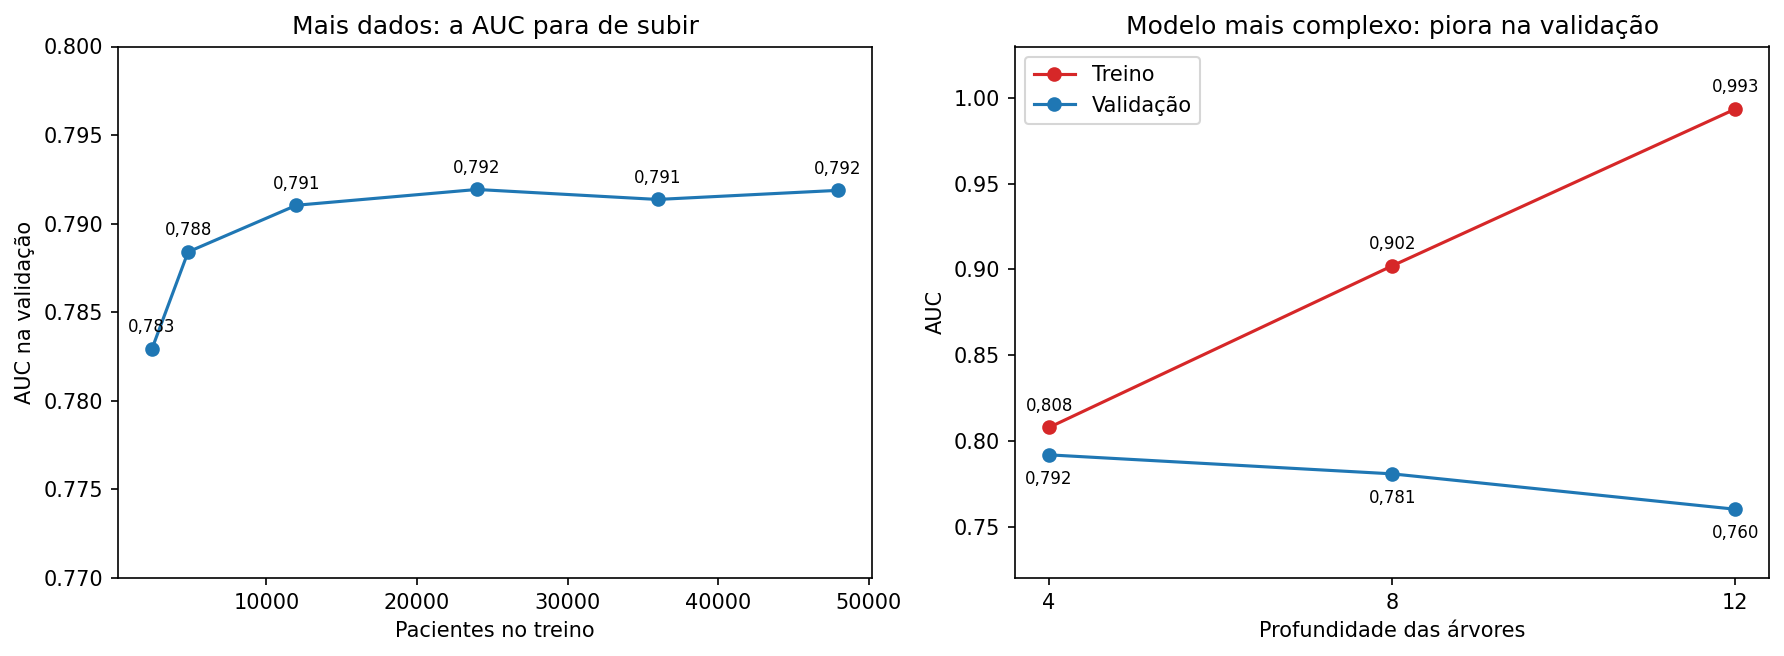

- **Mais dados:** AUC de 0,783 com 2.397 pacientes, 0,791 com 11.988,
  0,792 com 23.977 e 0,792 com 47.955.
- **Modelo mais complexo:** profundidade 4, 8 e 12: AUC no treino 0,808, 0,902 e 0,993;
  na validação 0,792, 0,781 e 0,760.
- **Combinar modelos:** média de Regressão Logística, Random Forest e XGBoost: AUC 0,7906; média dos cinco: 0,7914;
  melhor modelo sozinho: 0,7919.
- **Pressão arterial:** só as duas pressões dão AUC de 0,746 (contra 0,792 com as 11 variáveis).
  97% das sistólicas e 97% das diastólicas terminam em 0; 43% dos pacientes têm exatamente 120/80 ou 140/90.

In [7]:
X_train, X_val, _, y_train, _, _ = load_splits("A", save_ids=False)

# 1) mais dados: o desempenho para de melhorar?
fracoes = [0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
curva_aprendizado = []
for fracao in fracoes:
    idx = X_train.sample(int(len(X_train) * fracao), random_state=SEED).index
    modelo = xgb.build_model(X_train.loc[idx]).fit(X_train.loc[idx], y_train.loc[idx])
    curva_aprendizado.append(roc_auc_score(y_val, modelo.predict_proba(X_val)[:, 1]))

# 2) modelo mais complexo: ajusta melhor o treino e piora na validação?
profundidades, auc_treino, auc_val = [4, 8, 12], [], []
for d, n_arvores, taxa in ((4, 200, 0.03), (8, 600, 0.05), (12, 800, 0.05)):
    modelo = Pipeline([("prep", build_preprocessor(X_train, scale=False)),
                       ("model", XGBClassifier(max_depth=d, n_estimators=n_arvores, learning_rate=taxa, subsample=0.8,
                                               colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED))]).fit(X_train, y_train)
    auc_treino.append(roc_auc_score(y_train, modelo.predict_proba(X_train)[:, 1]))
    auc_val.append(roc_auc_score(y_val, modelo.predict_proba(X_val)[:, 1]))

# 3) combinar modelos: a média das probabilidades supera o melhor modelo?
media3 = np.mean([probs[m] for m in ("logistic", "random_forest", "xgb")], axis=0)
media5 = np.mean(list(probs.values()), axis=0)
melhor_unico = max(roc_auc_score(y_val, p) for p in probs.values())

# 4) quanto cada pressão arterial carrega, e com que precisão foi medida?
pressoes = ["ap_hi", "ap_lo"]
so_pressao = Pipeline([("prep", build_preprocessor(X_train[pressoes], scale=False)),
                       ("model", XGBClassifier(max_depth=3, n_estimators=200, learning_rate=0.05, tree_method="hist", random_state=SEED))]).fit(X_train[pressoes], y_train)
auc_pressao = roc_auc_score(y_val, so_pressao.predict_proba(X_val[pressoes])[:, 1])
termina_em_zero = {c: float((X_train[c] % 10 == 0).mean()) for c in pressoes}
comum = float((((X_train.ap_hi == 120) & (X_train.ap_lo == 80)) | ((X_train.ap_hi == 140) & (X_train.ap_lo == 90))).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot([f * len(X_train) for f in fracoes], curva_aprendizado, "o-", color="tab:blue")
ax1.set(title="Mais dados: a AUC para de subir", xlabel="Pacientes no treino", ylabel="AUC na validação", ylim=(0.77, 0.80))
for f, v in zip(fracoes, curva_aprendizado):
    ax1.annotate(num(v, 3), (f * len(X_train), v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax2.plot(profundidades, auc_treino, "o-", color="tab:red", label="Treino")
ax2.plot(profundidades, auc_val, "o-", color="tab:blue", label="Validação")
ax2.set(title="Modelo mais complexo: piora na validação", xlabel="Profundidade das árvores", ylabel="AUC", xticks=profundidades, ylim=(0.72, 1.03))
for d, a, b in zip(profundidades, auc_treino, auc_val):
    ax2.annotate(num(a, 3), (d, a), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax2.annotate(num(b, 3), (d, b), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
ax2.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "t33_limite_do_desempenho.png", dpi=150, bbox_inches="tight")
plt.close(fig)
mostrar(FIGURES_DIR / "t33_limite_do_desempenho.png")

texto(f"""- **Mais dados:** AUC de {num(curva_aprendizado[0], 3)} com {inteiro(len(X_train) * fracoes[0])} pacientes, {num(curva_aprendizado[2], 3)} com {inteiro(len(X_train) * fracoes[2])},
  {num(curva_aprendizado[3], 3)} com {inteiro(len(X_train) * fracoes[3])} e {num(curva_aprendizado[-1], 3)} com {inteiro(len(X_train))}.
- **Modelo mais complexo:** profundidade {profundidades[0]}, {profundidades[1]} e {profundidades[2]}: AUC no treino {num(auc_treino[0], 3)}, {num(auc_treino[1], 3)} e {num(auc_treino[2], 3)};
  na validação {num(auc_val[0], 3)}, {num(auc_val[1], 3)} e {num(auc_val[2], 3)}.
- **Combinar modelos:** média de Regressão Logística, Random Forest e XGBoost: AUC {num(roc_auc_score(y_val, media3), 4)}; média dos cinco: {num(roc_auc_score(y_val, media5), 4)};
  melhor modelo sozinho: {num(melhor_unico, 4)}.
- **Pressão arterial:** só as duas pressões dão AUC de {num(auc_pressao, 3)} (contra {num(roc_auc_score(y_val, probs["xgb"]), 3)} com as 11 variáveis).
  {pct(termina_em_zero["ap_hi"])} das sistólicas e {pct(termina_em_zero["ap_lo"])} das diastólicas terminam em 0; {pct(comum)} dos pacientes têm exatamente 120/80 ou 140/90.""")

## 6. Interpretação: importância das variáveis e SHAP (seção 7)

Importância por permutação, importância nativa e odds ratio (T24) com os três modelos treinados **só no treino** e avaliados na validação. O SHAP (T25) usa o **modelo final**
(treino + validação), como no `09_shap.ipynb`.

> Os valores do SHAP calculados aqui podem diferir cerca de 1 ponto percentual dos do `09_shap.ipynb`. O relatório cita os valores do `09_shap.ipynb`,
> que é a fonte da T25; os cortes de 130 mmHg e 55 anos são os mesmos nos dois.

In [8]:
modelos = {"Regressão Logística": logistic, "Random Forest": random_forest, "XGBoost": xgb}
treinados = {nome: modulo.build_model(X_train).fit(X_train, y_train) for nome, modulo in modelos.items()}

perm = {nome: importancia_por_permutacao(m, X_val, y_val, n_repeats=10) for nome, m in treinados.items()}
nativa = {"Random Forest": importancia_nativa(treinados["Random Forest"]), "XGBoost": importancia_nativa(treinados["XGBoost"])}
odds = odds_ratios_clinicos(treinados["Regressão Logística"]).set_index("variavel")

topo3 = {nome: list(t["variavel"].head(3)) for nome, t in perm.items()}
sist, idade, colest = topo3["XGBoost"]
print("três primeiras (permutação):", topo3)
for nome, t in perm.items():
    t = t.set_index("variavel")
    print(f"queda de AUC ao embaralhar {sist}: {nome} = {num(t.loc[sist, 'queda_media'], 3)}; {idade} = {num(t.loc[idade, 'queda_media'], 3)}; {colest} = {num(t.loc[colest, 'queda_media'], 3)}")
diast = "Pressão diastólica (mmHg)"
for nome, t in nativa.items():
    ordem_nativa = list(t["variavel"]).index(diast) + 1
    ordem_perm = list(perm[nome]["variavel"]).index(diast) + 1
    print(f"{diast} no {nome}: {ordem_nativa}ª na importância nativa ({pct(t.set_index('variavel').loc[diast, 'importancia'])}) e {ordem_perm}ª na permutação")
print(f"odds ratio da sistólica por 10 mmHg: {num(odds.loc[sist, 'odds_ratio'])} | idade por 5 anos: {num(odds.loc[idade, 'odds_ratio'])} | colesterol por nível: {num(odds.loc[colest, 'odds_ratio'])}")
for v in ("Fumante", "Consome álcool", "Glicose (nível 1–3)", "Fisicamente ativo"):
    print(f"odds ratio de {v}: {num(odds.loc[v, 'odds_ratio'])}")
corr_pressoes = X_train["ap_hi"].corr(X_train["ap_lo"])
print("correlação entre sistólica e diastólica:", num(corr_pressoes))

três primeiras (permutação): {'Regressão Logística': ['Pressão sistólica (mmHg)', 'Idade (anos)', 'Colesterol (nível 1–3)'], 'Random Forest': ['Pressão sistólica (mmHg)', 'Idade (anos)', 'Colesterol (nível 1–3)'], 'XGBoost': ['Pressão sistólica (mmHg)', 'Idade (anos)', 'Colesterol (nível 1–3)']}
queda de AUC ao embaralhar Pressão sistólica (mmHg): Regressão Logística = 0,161; Idade (anos) = 0,028; Colesterol (nível 1–3) = 0,025
queda de AUC ao embaralhar Pressão sistólica (mmHg): Random Forest = 0,162; Idade (anos) = 0,032; Colesterol (nível 1–3) = 0,027
queda de AUC ao embaralhar Pressão sistólica (mmHg): XGBoost = 0,160; Idade (anos) = 0,034; Colesterol (nível 1–3) = 0,027
Pressão diastólica (mmHg) no Random Forest: 2ª na importância nativa (20%) e 4ª na permutação
Pressão diastólica (mmHg) no XGBoost: 2ª na importância nativa (17%) e 5ª na permutação
odds ratio da sistólica por 10 mmHg: 1,75 | idade por 5 anos: 1,29 | colesterol por nível: 1,64
odds ratio de Fumante: 0,86
odds ratio

In [9]:
if not FINAL_MODEL_PATH.exists():
    train_final_model()  # grava models/final_model.joblib (ignorado pelo Git), como no 09_shap.ipynb
artefato = joblib.load(FINAL_MODEL_PATH)
assert artefato["modelo"] == "xgb" and artefato["features"] == "A" and artefato["threshold"] == LIMIAR_FINAL

explicacao, _ = shap_values(artefato["model"], X_val, sample_size=1500)
importancia = pd.Series(np.abs(explicacao.values).mean(axis=0), index=explicacao.feature_names).sort_values(ascending=False)
participacao = importancia / importancia.sum()
faixas_p = shap_por_faixa(explicacao, "Pressão sistólica (mmHg)", [0, 110, 120, 130, 140, 150, 160, 180, 251])
faixas_i = shap_por_faixa(explicacao, "Idade (anos)", [0, 40, 45, 50, 55, 60, 70])
corte_p = int(faixas_p[faixas_p["shap_medio"] > 0].iloc[0]["faixa"].left)
corte_i = int(faixas_i[faixas_i["shap_medio"] > 0].iloc[0]["faixa"].left)

print("SHAP, participação das três primeiras:", {v: pct(participacao[v]) for v in participacao.index[:3]}, "| soma:", pct(participacao.iloc[:3].sum()))
print(f"pressão sistólica passa a aumentar o risco a partir de {corte_p} mmHg | idade a partir de {corte_i} anos")
print(f"contribuição média da sistólica: {num(faixas_p['shap_medio'].iloc[0])} (faixa mais baixa) e {num(faixas_p['shap_medio'].iloc[-1])} (faixa mais alta)")
faixas_p.round(2)

Treinando xgb com conjunto A...
Total de pacientes: 58232


Modelo final salvo em: models/final_model.joblib
Limiar fixo: 0.36


SHAP, participação das três primeiras: {'Pressão sistólica (mmHg)': '46%', 'Idade (anos)': '17%', 'Colesterol (nível 1–3)': '13%'} | soma: 76%
pressão sistólica passa a aumentar o risco a partir de 130 mmHg | idade a partir de 55 anos
contribuição média da sistólica: -1,04 (faixa mais baixa) e 1,35 (faixa mais alta)


,faixa,pacientes,shap_medio
0,"[0, 110)",75,-1.04
1,"[110, 120)",216,-0.84
2,"[120, 130)",580,-0.51
3,"[130, 140)",209,0.23
4,"[140, 150)",218,1.18
5,"[150, 160)",92,1.37
6,"[160, 180)",88,1.34
7,"[180, 251)",22,1.35
